In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_excel("1553768847_housing.xlsx")

In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  int64  
 3   total_rooms         20640 non-null  int64  
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  int64  
 6   households          20640 non-null  int64  
 7   median_income       20640 non-null  float64
 8   ocean_proximity     20640 non-null  object 
 9   median_house_value  20640 non-null  int64  
dtypes: float64(4), int64(5), object(1)
memory usage: 1.6+ MB


In [4]:
data.isna().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
ocean_proximity         0
median_house_value      0
dtype: int64

In [5]:
data["total_bedrooms"] = data["total_bedrooms"].fillna(data["total_bedrooms"].mean())

In [6]:
data.isna().sum()

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
ocean_proximity       0
median_house_value    0
dtype: int64

In [7]:
data.head(20)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity,median_house_value
0,-122.23,37.88,41,880,129.0,322,126,8.3252,NEAR BAY,452600
1,-122.22,37.86,21,7099,1106.0,2401,1138,8.3014,NEAR BAY,358500
2,-122.24,37.85,52,1467,190.0,496,177,7.2574,NEAR BAY,352100
3,-122.25,37.85,52,1274,235.0,558,219,5.6431,NEAR BAY,341300
4,-122.25,37.85,52,1627,280.0,565,259,3.8462,NEAR BAY,342200
5,-122.25,37.85,52,919,213.0,413,193,4.0368,NEAR BAY,269700
6,-122.25,37.84,52,2535,489.0,1094,514,3.6591,NEAR BAY,299200
7,-122.25,37.84,52,3104,687.0,1157,647,3.1200,NEAR BAY,241400
8,-122.26,37.84,42,2555,665.0,1206,595,2.0804,NEAR BAY,226700
9,-122.25,37.84,52,3549,707.0,1551,714,3.6912,NEAR BAY,261100


In [8]:
label_encoder = LabelEncoder()

In [9]:
data["ocean_proximity"] = label_encoder.fit_transform(data["ocean_proximity"])

In [10]:
data["ocean_proximity"].unique()

array([3, 0, 1, 4, 2])

In [11]:
data.values

array([[-1.2223e+02,  3.7880e+01,  4.1000e+01, ...,  8.3252e+00,
         3.0000e+00,  4.5260e+05],
       [-1.2222e+02,  3.7860e+01,  2.1000e+01, ...,  8.3014e+00,
         3.0000e+00,  3.5850e+05],
       [-1.2224e+02,  3.7850e+01,  5.2000e+01, ...,  7.2574e+00,
         3.0000e+00,  3.5210e+05],
       ...,
       [-1.2122e+02,  3.9430e+01,  1.7000e+01, ...,  1.7000e+00,
         1.0000e+00,  9.2300e+04],
       [-1.2132e+02,  3.9430e+01,  1.8000e+01, ...,  1.8672e+00,
         1.0000e+00,  8.4700e+04],
       [-1.2124e+02,  3.9370e+01,  1.6000e+01, ...,  2.3886e+00,
         1.0000e+00,  8.9400e+04]])

In [12]:
len(data.columns)

10

In [13]:
data.corr()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity,median_house_value
longitude,1.000000,-0.924664,-0.108197,0.044568,0.069260,0.099773,0.055310,-0.015176,-0.289779,-0.045967
latitude,-0.924664,1.000000,0.011173,-0.036100,-0.066658,-0.108785,-0.071035,-0.079809,0.200974,-0.144160
housing_median_age,-0.108197,0.011173,1.000000,-0.361262,-0.318998,-0.296244,-0.302916,-0.119034,0.112468,0.105623
total_rooms,0.044568,-0.036100,-0.361262,1.000000,0.927253,0.857126,0.918484,0.198050,-0.015693,0.134153
total_bedrooms,0.069260,-0.066658,-0.318998,0.927253,1.000000,0.873910,0.974725,-0.007682,-0.014688,0.049454
population,0.099773,-0.108785,-0.296244,0.857126,0.873910,1.000000,0.907222,0.004834,-0.070282,-0.024650
households,0.055310,-0.071035,-0.302916,0.918484,0.974725,0.907222,1.000000,0.013033,-0.018186,0.065843
median_income,-0.015176,-0.079809,-0.119034,0.198050,-0.007682,0.004834,0.013033,1.000000,-0.014957,0.688075
ocean_proximity,-0.289779,0.200974,0.112468,-0.015693,-0.014688,-0.070282,-0.018186,-0.014957,1.000000,0.081750
median_house_value,-0.045967,-0.144160,0.105623,0.134153,0.049454,-0.024650,0.065843,0.688075,0.081750,1.000000


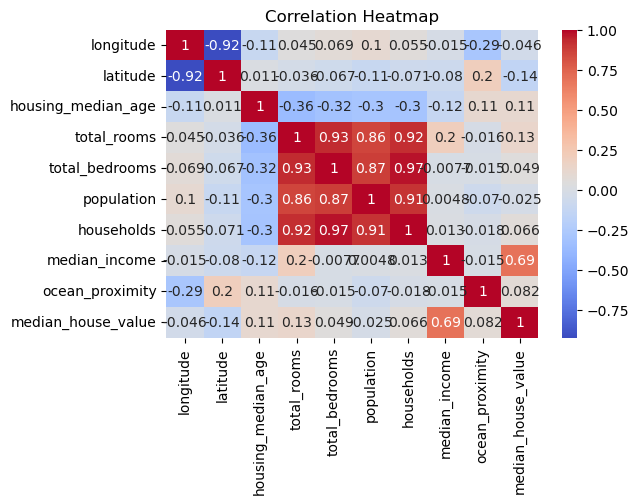

In [14]:
plt.figure(figsize=(6, 4))
sns.heatmap(data.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()


In [15]:
X = data.drop(columns=["median_house_value"])
y = data["median_house_value"]

In [16]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [17]:
xgb_model = XGBRegressor()

In [18]:
xgb_model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=None, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=None, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=None, n_jobs=None,
             num_parallel_tree=None, random_state=None, ...)

In [19]:
predictions = xgb_model.predict(X_test)
predictions

array([ 47510.19,  76155.06, 524512.9 , ..., 480536.44,  81416.01,
       163550.47], dtype=float32)

In [20]:
from sklearn.metrics import r2_score, mean_absolute_error, accuracy_score

In [21]:
model_score = r2_score(y_test, predictions)
model_score

0.8211983852840421

In [22]:
mae_score = mean_absolute_error(y_test, predictions)
mae_score

32176.491994931715

In [23]:
import joblib

In [24]:
joblib.dump(xgb_model, "xgb_trained_model")

['xgb_trained_model']

In [25]:
model = joblib.load("xgb_trained_model")

In [26]:
model.predict(X_train)

array([115610.336, 351325.53 , 183109.94 , ..., 240877.2  , 278259.4  ,
       305299.03 ], dtype=float32)

In [27]:
from sklearn import model_selection

In [28]:
results = model_selection.cross_val_score(model, X, y)
print(results)

[0.63845872 0.63269254 0.70971592 0.53698031 0.66479379]


In [29]:
from sklearn.ensemble import AdaBoostRegressor, RandomForestRegressor

In [30]:
ada_model = AdaBoostRegressor()
ada_model.fit(X_train, y_train)

AdaBoostRegressor()

In [31]:
ada_predictions = ada_model.predict(X_test)

In [32]:
results = model_selection.cross_val_score(ada_model, X, y)
print(results)

[-0.09112875  0.24547972  0.52816243  0.20659327  0.55350737]


In [33]:
scores = r2_score(y_test, ada_predictions)
scores

0.37611844899232527

In [34]:
rf_model = RandomForestRegressor()
rf_model.fit(X_train, y_train)

RandomForestRegressor()

In [35]:
rf_predictions = rf_model.predict(X_test)
rf_predictions

array([ 55749.  ,  66953.  , 471063.45, ..., 498483.97,  69518.  ,
       172114.  ])

In [36]:
validate = model_selection.cross_val_score(rf_model, X, y)
validate

array([0.45816663, 0.62475754, 0.7022754 , 0.10620808, 0.66615808])

In [37]:
r2_score(y_test, rf_predictions)

0.809927981692304

In [40]:
from catboost import CatBoostRegressor

In [41]:
cat_model = CatBoostRegressor()
cat_model.fit(X_train, y_train)

Learning rate set to 0.063766
0:	learn: 111443.9176455	total: 60.9ms	remaining: 1m
1:	learn: 107664.0242699	total: 70.8ms	remaining: 35.3s
2:	learn: 104127.9840679	total: 79ms	remaining: 26.3s
3:	learn: 101021.5232239	total: 87.2ms	remaining: 21.7s
4:	learn: 98287.6280240	total: 95.2ms	remaining: 19s
5:	learn: 95513.1818538	total: 103ms	remaining: 17.1s
6:	learn: 93274.7037606	total: 112ms	remaining: 15.9s
7:	learn: 91254.6081447	total: 120ms	remaining: 14.9s
8:	learn: 89038.7002589	total: 131ms	remaining: 14.4s
9:	learn: 87224.2873389	total: 139ms	remaining: 13.8s
10:	learn: 85439.4101702	total: 147ms	remaining: 13.2s
11:	learn: 83865.1119089	total: 153ms	remaining: 12.6s
12:	learn: 82512.3444758	total: 158ms	remaining: 12s
13:	learn: 80992.1082074	total: 162ms	remaining: 11.4s
14:	learn: 79801.6558662	total: 166ms	remaining: 10.9s
15:	learn: 78421.7436591	total: 170ms	remaining: 10.4s
16:	learn: 77213.8724456	total: 173ms	remaining: 10s
17:	learn: 75992.0270753	total: 176ms	remaining

197:	learn: 48733.0414828	total: 575ms	remaining: 2.33s
198:	learn: 48705.2282809	total: 578ms	remaining: 2.33s
199:	learn: 48663.6525534	total: 581ms	remaining: 2.32s
200:	learn: 48633.3537763	total: 583ms	remaining: 2.32s
201:	learn: 48604.0084854	total: 586ms	remaining: 2.31s
202:	learn: 48547.2962715	total: 588ms	remaining: 2.31s
203:	learn: 48510.5900359	total: 591ms	remaining: 2.31s
204:	learn: 48468.2564751	total: 593ms	remaining: 2.3s
205:	learn: 48412.8315195	total: 596ms	remaining: 2.3s
206:	learn: 48383.9875750	total: 599ms	remaining: 2.29s
207:	learn: 48352.7869034	total: 602ms	remaining: 2.29s
208:	learn: 48313.8692003	total: 606ms	remaining: 2.29s
209:	learn: 48284.9758062	total: 608ms	remaining: 2.29s
210:	learn: 48229.1507951	total: 610ms	remaining: 2.28s
211:	learn: 48189.8365980	total: 612ms	remaining: 2.27s
212:	learn: 48133.3488191	total: 614ms	remaining: 2.27s
213:	learn: 48096.0426765	total: 617ms	remaining: 2.26s
214:	learn: 48048.1809246	total: 619ms	remaining: 

370:	learn: 43968.4674012	total: 969ms	remaining: 1.64s
371:	learn: 43944.0429292	total: 973ms	remaining: 1.64s
372:	learn: 43909.8935286	total: 976ms	remaining: 1.64s
373:	learn: 43897.9396251	total: 980ms	remaining: 1.64s
374:	learn: 43874.5659392	total: 983ms	remaining: 1.64s
375:	learn: 43859.7331133	total: 986ms	remaining: 1.64s
376:	learn: 43850.7628696	total: 990ms	remaining: 1.64s
377:	learn: 43832.9998135	total: 994ms	remaining: 1.64s
378:	learn: 43819.3962781	total: 999ms	remaining: 1.64s
379:	learn: 43802.9745961	total: 1s	remaining: 1.64s
380:	learn: 43791.6852593	total: 1.01s	remaining: 1.64s
381:	learn: 43775.8707496	total: 1.01s	remaining: 1.64s
382:	learn: 43762.8355603	total: 1.01s	remaining: 1.63s
383:	learn: 43743.5620657	total: 1.02s	remaining: 1.63s
384:	learn: 43728.6451117	total: 1.02s	remaining: 1.63s
385:	learn: 43715.2257295	total: 1.02s	remaining: 1.63s
386:	learn: 43694.3965141	total: 1.03s	remaining: 1.63s
387:	learn: 43677.8750596	total: 1.03s	remaining: 1

579:	learn: 40634.6175934	total: 1.55s	remaining: 1.12s
580:	learn: 40618.6798248	total: 1.56s	remaining: 1.12s
581:	learn: 40610.1978370	total: 1.56s	remaining: 1.12s
582:	learn: 40598.2354135	total: 1.56s	remaining: 1.12s
583:	learn: 40581.0448963	total: 1.56s	remaining: 1.11s
584:	learn: 40569.0971199	total: 1.57s	remaining: 1.11s
585:	learn: 40558.6593855	total: 1.57s	remaining: 1.11s
586:	learn: 40549.7481515	total: 1.58s	remaining: 1.11s
587:	learn: 40538.0425758	total: 1.59s	remaining: 1.11s
588:	learn: 40532.6197157	total: 1.59s	remaining: 1.11s
589:	learn: 40517.8661224	total: 1.59s	remaining: 1.1s
590:	learn: 40490.5108928	total: 1.59s	remaining: 1.1s
591:	learn: 40478.8753149	total: 1.6s	remaining: 1.1s
592:	learn: 40466.8913571	total: 1.6s	remaining: 1.1s
593:	learn: 40447.6212585	total: 1.6s	remaining: 1.09s
594:	learn: 40437.1311838	total: 1.6s	remaining: 1.09s
595:	learn: 40424.6353146	total: 1.61s	remaining: 1.09s
596:	learn: 40403.0056813	total: 1.61s	remaining: 1.09s


784:	learn: 38214.6944025	total: 2.13s	remaining: 585ms
785:	learn: 38201.1478859	total: 2.14s	remaining: 582ms
786:	learn: 38192.6694523	total: 2.14s	remaining: 580ms
787:	learn: 38185.1153871	total: 2.14s	remaining: 577ms
788:	learn: 38176.0270238	total: 2.15s	remaining: 574ms
789:	learn: 38166.8187656	total: 2.15s	remaining: 571ms
790:	learn: 38153.3839108	total: 2.15s	remaining: 569ms
791:	learn: 38136.9073558	total: 2.15s	remaining: 566ms
792:	learn: 38121.5399592	total: 2.16s	remaining: 564ms
793:	learn: 38111.4251490	total: 2.16s	remaining: 561ms
794:	learn: 38102.7579505	total: 2.17s	remaining: 559ms
795:	learn: 38091.4406798	total: 2.17s	remaining: 557ms
796:	learn: 38074.9126485	total: 2.18s	remaining: 555ms
797:	learn: 38068.6083038	total: 2.18s	remaining: 553ms
798:	learn: 38059.5750759	total: 2.21s	remaining: 556ms
799:	learn: 38047.2212379	total: 2.23s	remaining: 557ms
800:	learn: 38035.2819240	total: 2.24s	remaining: 556ms
801:	learn: 38022.2149597	total: 2.25s	remaining

944:	learn: 36681.6326052	total: 2.73s	remaining: 159ms
945:	learn: 36672.6516470	total: 2.73s	remaining: 156ms
946:	learn: 36664.6540093	total: 2.74s	remaining: 153ms
947:	learn: 36658.1861221	total: 2.74s	remaining: 150ms
948:	learn: 36651.0931919	total: 2.74s	remaining: 147ms
949:	learn: 36640.6473405	total: 2.75s	remaining: 145ms
950:	learn: 36628.2841022	total: 2.75s	remaining: 142ms
951:	learn: 36622.7061986	total: 2.75s	remaining: 139ms
952:	learn: 36613.5556762	total: 2.75s	remaining: 136ms
953:	learn: 36606.2697568	total: 2.76s	remaining: 133ms
954:	learn: 36598.7046402	total: 2.76s	remaining: 130ms
955:	learn: 36586.8708021	total: 2.76s	remaining: 127ms
956:	learn: 36578.5586111	total: 2.77s	remaining: 124ms
957:	learn: 36569.4477818	total: 2.77s	remaining: 121ms
958:	learn: 36561.4305711	total: 2.77s	remaining: 119ms
959:	learn: 36553.8793898	total: 2.78s	remaining: 116ms
960:	learn: 36545.4510444	total: 2.78s	remaining: 113ms
961:	learn: 36538.5244367	total: 2.78s	remaining

In [42]:
cat_predictions = cat_model.predict(X_train)
cat_predictions

array([119121.85507112, 328029.26985392, 181023.15500446, ...,
       241432.41558793, 272780.44330267, 341118.96327651])

In [43]:
cat_predictions = len(y_test)

In [45]:
validation = model_selection.cross_val_score(cat_model, X, y,)
validation

Learning rate set to 0.063766
0:	learn: 111868.2867650	total: 6.42ms	remaining: 6.42s
1:	learn: 107933.8559654	total: 10.5ms	remaining: 5.25s
2:	learn: 104420.1233510	total: 14.1ms	remaining: 4.68s
3:	learn: 101193.2523853	total: 17.2ms	remaining: 4.27s
4:	learn: 98370.8466969	total: 20.2ms	remaining: 4.01s
5:	learn: 95654.8474360	total: 22.9ms	remaining: 3.79s
6:	learn: 93422.9302613	total: 25.3ms	remaining: 3.59s
7:	learn: 91259.8978124	total: 27.9ms	remaining: 3.45s
8:	learn: 89106.0310443	total: 30.3ms	remaining: 3.33s
9:	learn: 87301.8193393	total: 32.5ms	remaining: 3.21s
10:	learn: 85436.6271550	total: 35.1ms	remaining: 3.16s
11:	learn: 83929.4315456	total: 37.3ms	remaining: 3.07s
12:	learn: 82528.0346187	total: 39.4ms	remaining: 2.99s
13:	learn: 81139.8332023	total: 41.4ms	remaining: 2.92s
14:	learn: 79814.8931598	total: 43.4ms	remaining: 2.85s
15:	learn: 78554.5411775	total: 45.5ms	remaining: 2.8s
16:	learn: 77544.2815714	total: 47.5ms	remaining: 2.75s
17:	learn: 76655.1018759	

171:	learn: 51046.0963624	total: 379ms	remaining: 1.82s
172:	learn: 50992.2141209	total: 381ms	remaining: 1.82s
173:	learn: 50956.9912461	total: 384ms	remaining: 1.82s
174:	learn: 50920.8337681	total: 386ms	remaining: 1.82s
175:	learn: 50875.3664673	total: 389ms	remaining: 1.82s
176:	learn: 50847.2835028	total: 391ms	remaining: 1.82s
177:	learn: 50798.7522779	total: 394ms	remaining: 1.82s
178:	learn: 50757.5081789	total: 397ms	remaining: 1.82s
179:	learn: 50701.3334013	total: 399ms	remaining: 1.82s
180:	learn: 50633.4610393	total: 402ms	remaining: 1.82s
181:	learn: 50589.8180995	total: 405ms	remaining: 1.82s
182:	learn: 50562.9067750	total: 407ms	remaining: 1.81s
183:	learn: 50534.2939795	total: 409ms	remaining: 1.81s
184:	learn: 50470.7308624	total: 411ms	remaining: 1.81s
185:	learn: 50443.3843639	total: 414ms	remaining: 1.81s
186:	learn: 50413.1871562	total: 416ms	remaining: 1.81s
187:	learn: 50365.3737367	total: 420ms	remaining: 1.81s
188:	learn: 50328.3805679	total: 422ms	remaining

351:	learn: 45552.8544669	total: 766ms	remaining: 1.41s
352:	learn: 45533.4310140	total: 768ms	remaining: 1.41s
353:	learn: 45518.8234631	total: 771ms	remaining: 1.41s
354:	learn: 45497.5079089	total: 773ms	remaining: 1.41s
355:	learn: 45474.2666420	total: 776ms	remaining: 1.4s
356:	learn: 45424.3181065	total: 779ms	remaining: 1.4s
357:	learn: 45407.9922214	total: 785ms	remaining: 1.41s
358:	learn: 45391.3041964	total: 794ms	remaining: 1.42s
359:	learn: 45379.3046061	total: 796ms	remaining: 1.41s
360:	learn: 45366.5733023	total: 799ms	remaining: 1.41s
361:	learn: 45347.7156693	total: 802ms	remaining: 1.41s
362:	learn: 45322.8615836	total: 806ms	remaining: 1.41s
363:	learn: 45281.0044729	total: 809ms	remaining: 1.41s
364:	learn: 45233.7077381	total: 812ms	remaining: 1.41s
365:	learn: 45213.7259560	total: 815ms	remaining: 1.41s
366:	learn: 45198.7730674	total: 819ms	remaining: 1.41s
367:	learn: 45184.2416045	total: 821ms	remaining: 1.41s
368:	learn: 45159.7756104	total: 823ms	remaining: 

574:	learn: 41782.3917031	total: 1.35s	remaining: 996ms
575:	learn: 41774.6261353	total: 1.35s	remaining: 993ms
576:	learn: 41751.1018274	total: 1.35s	remaining: 991ms
577:	learn: 41727.9613797	total: 1.35s	remaining: 989ms
578:	learn: 41715.5026266	total: 1.36s	remaining: 987ms
579:	learn: 41701.5929084	total: 1.36s	remaining: 986ms
580:	learn: 41689.1450237	total: 1.36s	remaining: 984ms
581:	learn: 41671.4020546	total: 1.37s	remaining: 982ms
582:	learn: 41659.8485569	total: 1.37s	remaining: 980ms
583:	learn: 41645.2557255	total: 1.37s	remaining: 977ms
584:	learn: 41628.0725441	total: 1.38s	remaining: 976ms
585:	learn: 41618.0409148	total: 1.38s	remaining: 973ms
586:	learn: 41607.9216561	total: 1.38s	remaining: 971ms
587:	learn: 41578.7511217	total: 1.38s	remaining: 969ms
588:	learn: 41570.1367256	total: 1.39s	remaining: 968ms
589:	learn: 41550.9038760	total: 1.39s	remaining: 966ms
590:	learn: 41540.6791534	total: 1.39s	remaining: 964ms
591:	learn: 41531.4789459	total: 1.4s	remaining:

738:	learn: 39731.5987397	total: 1.73s	remaining: 611ms
739:	learn: 39719.5988454	total: 1.73s	remaining: 609ms
740:	learn: 39706.4019711	total: 1.74s	remaining: 607ms
741:	learn: 39697.3464202	total: 1.74s	remaining: 605ms
742:	learn: 39681.8230487	total: 1.74s	remaining: 602ms
743:	learn: 39665.9224483	total: 1.74s	remaining: 600ms
744:	learn: 39652.8731198	total: 1.75s	remaining: 598ms
745:	learn: 39641.2768880	total: 1.75s	remaining: 596ms
746:	learn: 39632.5112650	total: 1.75s	remaining: 594ms
747:	learn: 39624.8994599	total: 1.76s	remaining: 592ms
748:	learn: 39616.3617083	total: 1.76s	remaining: 590ms
749:	learn: 39609.1249051	total: 1.76s	remaining: 587ms
750:	learn: 39599.1457949	total: 1.76s	remaining: 585ms
751:	learn: 39587.9059287	total: 1.77s	remaining: 583ms
752:	learn: 39575.5197808	total: 1.77s	remaining: 581ms
753:	learn: 39560.0180080	total: 1.77s	remaining: 578ms
754:	learn: 39549.4476158	total: 1.77s	remaining: 576ms
755:	learn: 39535.4685096	total: 1.78s	remaining

...

447:	learn: 40639.6645452	total: 970ms	remaining: 1.2s
448:	learn: 40622.2438039	total: 973ms	remaining: 1.19s
449:	learn: 40608.1046358	total: 976ms	remaining: 1.19s
450:	learn: 40589.5868578	total: 978ms	remaining: 1.19s
451:	learn: 40575.6290642	total: 981ms	remaining: 1.19s
452:	learn: 40557.1982589	total: 983ms	remaining: 1.19s
453:	learn: 40545.5107259	total: 986ms	remaining: 1.19s
454:	learn: 40526.2220976	total: 989ms	remaining: 1.18s
455:	learn: 40503.9481375	total: 993ms	remaining: 1.18s
456:	learn: 40481.2709514	total: 995ms	remaining: 1.18s
457:	learn: 40468.0650941	total: 999ms	remaining: 1.18s
458:	learn: 40441.1143705	total: 1s	remaining: 1.18s
459:	learn: 40430.9416264	total: 1s	remaining: 1.18s
460:	learn: 40418.0440947	total: 1.01s	remaining: 1.18s
461:	learn: 40398.2640540	total: 1.01s	remaining: 1.18s
462:	learn: 40384.4553455	total: 1.01s	remaining: 1.17s
463:	learn: 40376.1102115	total: 1.01s	remaining: 1.17s
464:	learn: 40354.2447056	total: 1.02s	remaining: 1.17s

608:	learn: 38345.3349581	total: 1.36s	remaining: 873ms
609:	learn: 38337.3833181	total: 1.36s	remaining: 871ms
610:	learn: 38326.8150975	total: 1.36s	remaining: 869ms
611:	learn: 38321.7235740	total: 1.37s	remaining: 867ms
612:	learn: 38309.9317219	total: 1.37s	remaining: 865ms
613:	learn: 38298.5629738	total: 1.37s	remaining: 863ms
614:	learn: 38288.7153686	total: 1.37s	remaining: 861ms
615:	learn: 38275.1332034	total: 1.38s	remaining: 859ms
616:	learn: 38265.8904089	total: 1.38s	remaining: 857ms
617:	learn: 38259.7509377	total: 1.38s	remaining: 855ms
618:	learn: 38249.9732874	total: 1.39s	remaining: 853ms
619:	learn: 38236.1272829	total: 1.39s	remaining: 851ms
620:	learn: 38227.6562949	total: 1.39s	remaining: 849ms
621:	learn: 38216.2846083	total: 1.39s	remaining: 847ms
622:	learn: 38200.8099028	total: 1.4s	remaining: 845ms
623:	learn: 38191.0468124	total: 1.4s	remaining: 843ms
624:	learn: 38181.5179262	total: 1.4s	remaining: 841ms
625:	learn: 38175.7226713	total: 1.4s	remaining: 83

795:	learn: 36247.7964064	total: 1.95s	remaining: 500ms
796:	learn: 36236.9021037	total: 1.96s	remaining: 498ms
797:	learn: 36230.9422458	total: 1.96s	remaining: 496ms
798:	learn: 36226.4269557	total: 1.96s	remaining: 494ms
799:	learn: 36214.6557164	total: 1.97s	remaining: 492ms
800:	learn: 36200.0144342	total: 1.97s	remaining: 490ms
801:	learn: 36193.2117692	total: 1.98s	remaining: 488ms
802:	learn: 36177.1754951	total: 1.98s	remaining: 486ms
803:	learn: 36168.4837349	total: 1.99s	remaining: 484ms
804:	learn: 36159.3198389	total: 1.99s	remaining: 482ms
805:	learn: 36154.7336947	total: 1.99s	remaining: 480ms
806:	learn: 36148.5765473	total: 2s	remaining: 478ms
807:	learn: 36143.1823594	total: 2s	remaining: 476ms
808:	learn: 36134.1256378	total: 2.01s	remaining: 474ms
809:	learn: 36126.0680110	total: 2.01s	remaining: 472ms
810:	learn: 36110.9470803	total: 2.02s	remaining: 470ms
811:	learn: 36100.3807366	total: 2.02s	remaining: 468ms
812:	learn: 36083.2587685	total: 2.03s	remaining: 467m

958:	learn: 34692.5107271	total: 2.54s	remaining: 108ms
959:	learn: 34684.7653347	total: 2.54s	remaining: 106ms
960:	learn: 34676.6940728	total: 2.54s	remaining: 103ms
961:	learn: 34660.1609788	total: 2.55s	remaining: 101ms
962:	learn: 34650.7011934	total: 2.55s	remaining: 98ms
963:	learn: 34644.2024238	total: 2.55s	remaining: 95.4ms
964:	learn: 34637.0217452	total: 2.56s	remaining: 92.8ms
965:	learn: 34631.2681751	total: 2.56s	remaining: 90.1ms
966:	learn: 34624.7612043	total: 2.56s	remaining: 87.5ms
967:	learn: 34615.2632277	total: 2.57s	remaining: 84.9ms
968:	learn: 34605.8869775	total: 2.57s	remaining: 82.3ms
969:	learn: 34595.7073703	total: 2.57s	remaining: 79.6ms
970:	learn: 34588.7075174	total: 2.58s	remaining: 77ms
971:	learn: 34580.6786238	total: 2.58s	remaining: 74.4ms
972:	learn: 34570.0110293	total: 2.58s	remaining: 71.8ms
973:	learn: 34559.7039351	total: 2.59s	remaining: 69.2ms
974:	learn: 34550.0980396	total: 2.59s	remaining: 66.5ms
975:	learn: 34541.9605128	total: 2.6s	r

array([0.66705033, 0.66598983, 0.73733437, 0.57332978, 0.70307941])